#### Question 2 - Anisotropic Diffusion

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import io, img_as_float
from skimage.color import rgb2gray
from skimage.metrics import peak_signal_noise_ratio as psnr, structural_similarity as ssim
from skimage.restoration import denoise_tv_bregman, denoise_tv_chambolle
from scipy.ndimage import gaussian_filter

load the image and add noise at 18.4 dB PSNR (parts a, b)

Target PSNR 18.4 dB  ->  noise sigma = 0.1202
Measured PSNR of noisy image: 18.39 dB


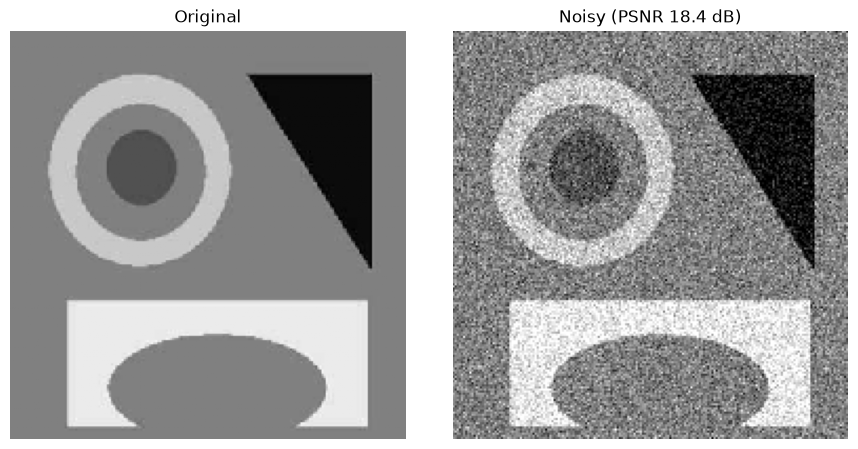

In [ ]:
rng = np.random.default_rng(0)

# --- Load original (float in [0,1], grayscale) ---
orig = img_as_float(io.imread('Synthetic_image.png'))
if orig.ndim == 3:
    orig = rgb2gray(orig[..., :3])

# --- Add Gaussian noise so that PSNR = 18.4 dB ---
# PSNR = 10*log10(MAX^2 / MSE), with MAX = 1  ->  MSE = 10^(-PSNR/10), sigma = sqrt(MSE)
target = 18.4
sigma = np.sqrt(10 ** (-target / 10))
print(f"Target PSNR {target} dB  ->  noise sigma = {sigma:.4f}")

def add_noise(img, sigma):
    return np.clip(img + rng.normal(0, sigma, img.shape), 0, 1)

noisy = add_noise(orig, sigma)

# Clipping reduces the noise a little, so measure it and nudge sigma until it matches
for _ in range(30):
    measured = psnr(orig, noisy, data_range=1)
    if abs(measured - target) < 0.02:
        break
    sigma *= 10 ** ((measured - target) / 20)
    noisy = add_noise(orig, sigma)
print(f"Measured PSNR of noisy image: {psnr(orig, noisy, data_range=1):.2f} dB")

# Noisy next to original
fig, ax = plt.subplots(1, 2, figsize=(9, 4.5))
ax[0].imshow(orig, cmap='gray', vmin=0, vmax=1); ax[0].set_title('Original')
ax[1].imshow(noisy, cmap='gray', vmin=0, vmax=1); ax[1].set_title(f'Noisy (PSNR {psnr(orig, noisy, data_range=1):.1f} dB)')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

Gaussian smoothing, TV, and Perona-Malik (parts c, d)

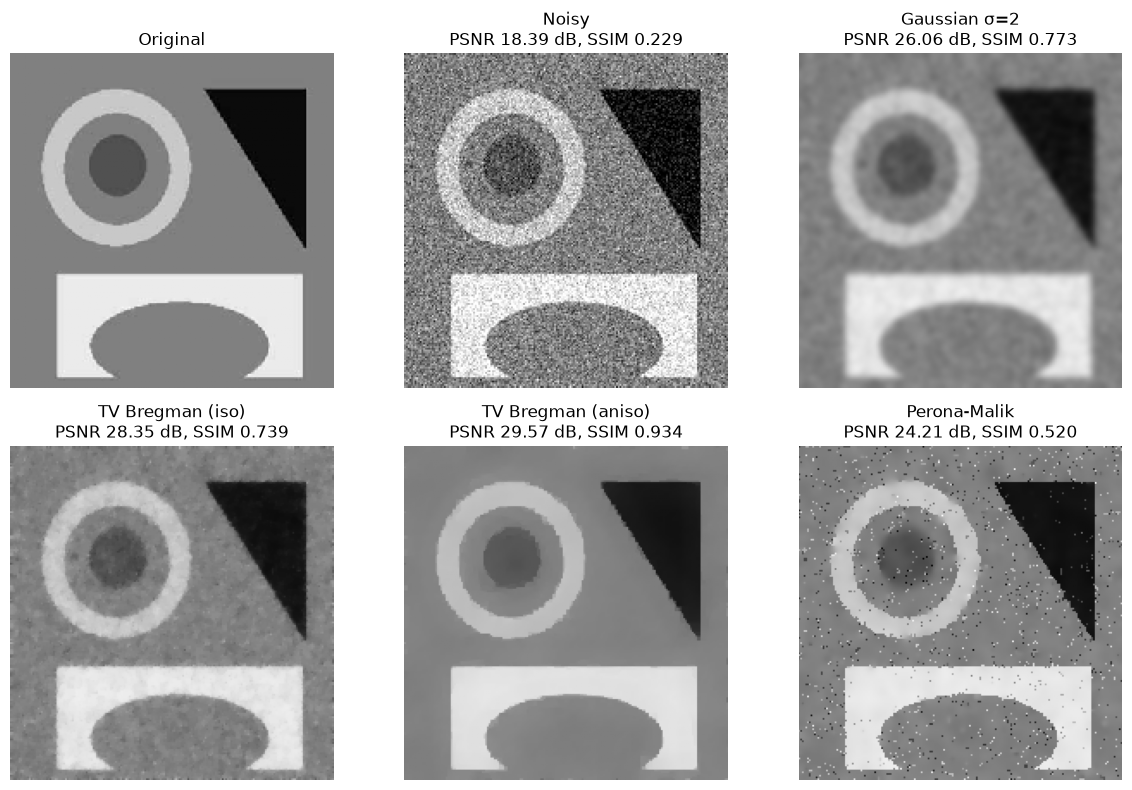

In [3]:
# --- c. Gaussian, sigma = 2 ---
gauss = gaussian_filter(noisy, sigma=2)

# --- d. Total variation (split Bregman). NOTE: smaller weight = MORE smoothing here ---
tv_iso   = denoise_tv_bregman(noisy, weight=5, isotropic=True)
tv_aniso = denoise_tv_bregman(noisy, weight=5, isotropic=False)

# --- Perona-Malik (simple implementation for comparison) ---
def perona_malik(img, n_iter=40, kappa=0.1, gamma=0.2):
    u = img.copy()
    g = lambda d: np.exp(-(d / kappa) ** 2)     # edge-stopping function
    for _ in range(n_iter):
        p = np.pad(u, 1, mode='edge')
        dN = p[:-2, 1:-1] - u; dS = p[2:, 1:-1] - u
        dE = p[1:-1, 2:] - u;  dW = p[1:-1, :-2] - u
        u = u + gamma * (g(dN)*dN + g(dS)*dS + g(dE)*dE + g(dW)*dW)
    return u

pm = perona_malik(noisy)

results = {'Noisy': noisy, 'Gaussian σ=2': gauss, 'TV Bregman (iso)': tv_iso,
           'TV Bregman (aniso)': tv_aniso, 'Perona-Malik': pm}

fig, ax = plt.subplots(2, 3, figsize=(12, 8))
ax = ax.ravel()
ax[0].imshow(orig, cmap='gray', vmin=0, vmax=1); ax[0].set_title('Original')
for a, (name, im) in zip(ax[1:], results.items()):
    a.imshow(im, cmap='gray', vmin=0, vmax=1)
    a.set_title(f'{name}\nPSNR {psnr(orig, im, data_range=1):.2f} dB, SSIM {ssim(orig, im, data_range=1):.3f}')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

tune the TV weight and compare edges (part d.iv)

weight=  1: PSNR=26.26 dB
weight=  2: PSNR=27.69 dB
weight=  3: PSNR=28.31 dB
weight=  5: PSNR=28.35 dB
weight=  8: PSNR=27.31 dB
weight= 12: PSNR=25.64 dB
weight= 20: PSNR=23.29 dB


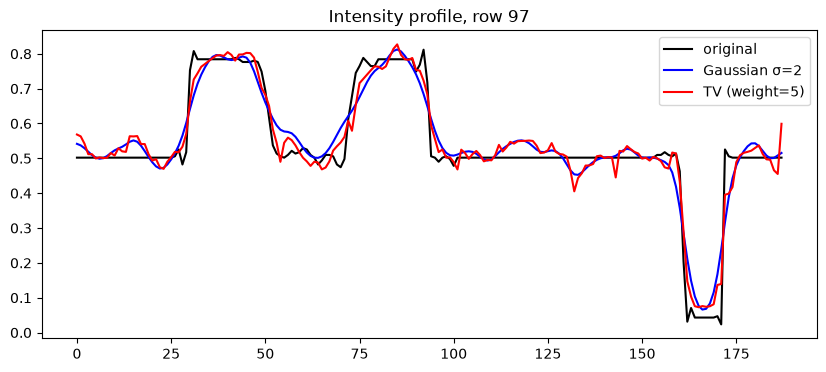

In [5]:
# Sweep the TV weight to find the best PSNR (and see the effect)
weights = [1, 2, 3, 5, 8, 12, 20]
scores = [psnr(orig, denoise_tv_bregman(noisy, weight=w, isotropic=True), data_range=1) for w in weights]
for w, s in zip(weights, scores): print(f"weight={w:>3}: PSNR={s:.2f} dB")
best_w = weights[int(np.argmax(scores))]
tv_best = denoise_tv_bregman(noisy, weight=best_w, isotropic=True)

# Edge profile through the middle row: TV keeps edges sharp, Gaussian smears them
row = orig.shape[0] // 2
plt.figure(figsize=(10, 4))
plt.plot(orig[row], 'k', label='original')
plt.plot(gauss[row], 'b', label='Gaussian σ=2')
plt.plot(tv_best[row], 'r', label=f'TV (weight={best_w})')
plt.legend(); plt.title(f'Intensity profile, row {row}'); plt.show()

TV on the nature_creek image, per channel (part d.v)

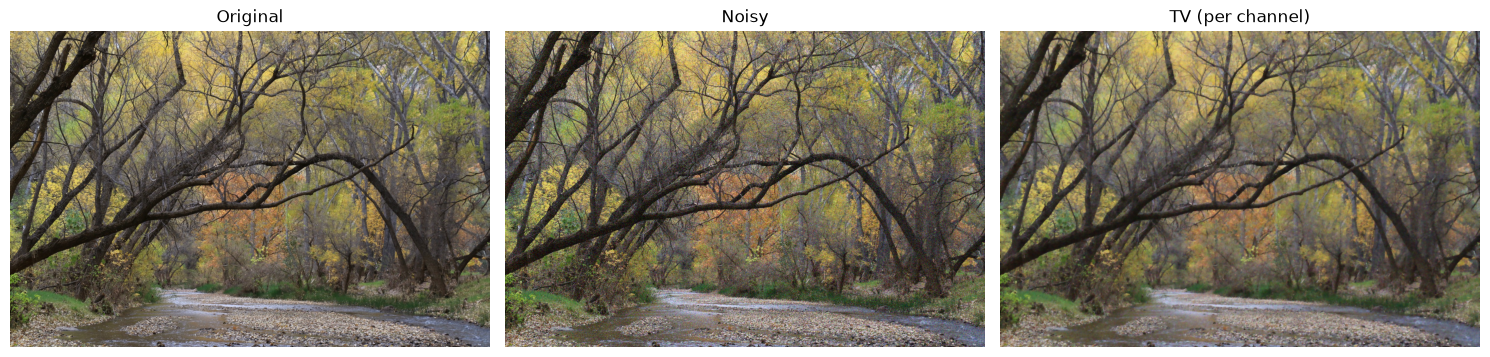

In [9]:
nature = img_as_float(io.imread('nature_creek.jpg'))   # adjust the filename/extension to yours
if nature.ndim == 3:
    nature = nature[..., :3]                            # drop alpha if present

# Optional: add noise first so the denoising is visible (skip if your image is already noisy)
nature_noisy = np.clip(nature + rng.normal(0, 0.1, nature.shape), 0, 1)

def tv_rgb(img, weight=5):
    out = np.zeros_like(img)
    for c in range(3):                                  # each channel independently
        out[..., c] = denoise_tv_bregman(img[..., c], weight=weight, isotropic=True)
    return np.clip(out, 0, 1)

nature_tv = tv_rgb(nature_noisy, weight=5)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, im, t in zip(ax, [nature, nature_noisy, nature_tv], ['Original', 'Noisy', 'TV (per channel)']):
    a.imshow(im); a.set_title(t); a.axis('off')
plt.tight_layout(); plt.show()

Noisy                  PSNR = 20.13 dB   SSIM = 0.498
TV weight=2            PSNR = 23.70 dB   SSIM = 0.555
TV weight=5            PSNR = 25.32 dB   SSIM = 0.685
TV weight=10           PSNR = 26.06 dB   SSIM = 0.736
TV weight=20           PSNR = 24.87 dB   SSIM = 0.690


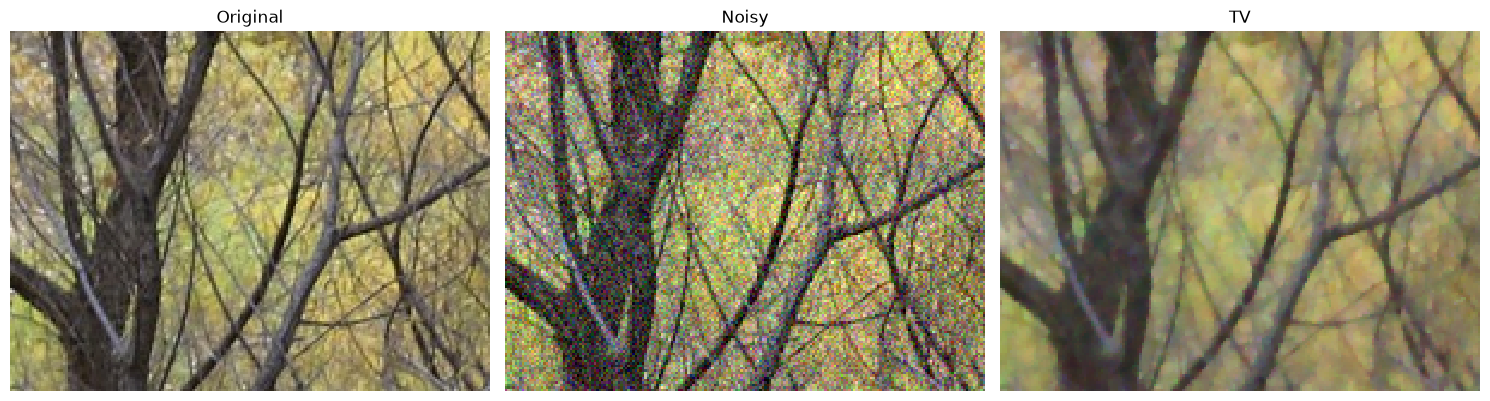

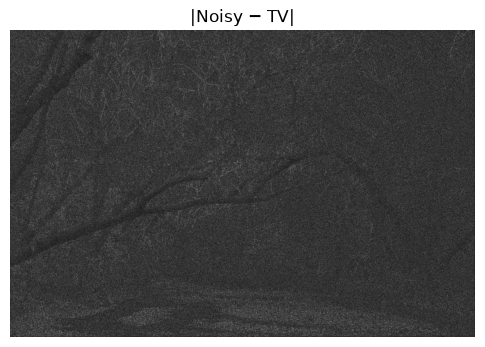

In [10]:
from skimage.metrics import peak_signal_noise_ratio as psnr, structural_similarity as ssim

# 1. Numbers: compare against the clean original (valid because we added the noise ourselves)
def report(name, im):
    p = psnr(nature, im, data_range=1)
    s = ssim(nature, im, data_range=1, channel_axis=2)
    print(f"{name:<22} PSNR = {p:.2f} dB   SSIM = {s:.3f}")

report("Noisy", nature_noisy)
for w in [2, 5, 10, 20]:
    report(f"TV weight={w}", tv_rgb(nature_noisy, weight=w))

# 2. Zoomed crop: pick a region with both branches and foliage
r0, r1, c0, c1 = 150, 300, 250, 450          # adjust to taste (rows, cols)
best = tv_rgb(nature_noisy, weight=5)         # change to the weight with the best PSNR

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, im, t in zip(ax, [nature, nature_noisy, best], ['Original', 'Noisy', 'TV']):
    a.imshow(im[r0:r1, c0:c1], interpolation='nearest')
    a.set_title(t); a.axis('off')
plt.tight_layout(); plt.show()

# 3. Difference image: what did TV remove? Should look like noise, not like edges
diff = np.abs(nature_noisy - best).mean(axis=2)
plt.figure(figsize=(6, 4)); plt.imshow(diff, cmap='gray'); plt.title('|Noisy − TV|'); plt.axis('off'); plt.show()